<a href="https://colab.research.google.com/github/Wesnei/experimento-PAA/blob/main/experimento_(PAA).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div align="center">
  <img src="https://github.com/sauloafoliveira/ppgcc-deep-learning/blob/main/ppgc_logo.png?raw=true" width="450">
  <br>
  <font size="4"><b>INSTITUTO FEDERAL DE EDUCAÇÃO, CIÊNCIA E TECNOLOGIA DO CEARÁ</b></font><br>
  <font size="3"><b>PROGRAMA DE PÓS-GRADUAÇÃO EM CIÊNCIA DA COMPUTAÇÃO - PPGCC</b></font><br>
  <font size="3">Mestrado Acadêmico em Ciência da Computação</font>
</div>

---
**Disciplina:** Projeto e Análise de Algoritmos – 2026.2  
**Docente:** Thiago Alves  
**Discentes:** Wesnei de Paiva Batista  
**Atividade:** Experimento de Análise de Algoritmos

---



# Configuração e Implementação dos 3 Algoritmos

Esta célula implementa o Algoritmo Guloso Ingênuo (razão valor/peso), o Força-Bruta Ingênuo ($O(2^n)$) e a Programação Dinâmica ($O(n \times W)$) com reconstrução completa dos itens selecionados, conforme exigido na especificação.

In [1]:
import time
import random
import numpy as np
import matplotlib.pyplot as plt

def mochila_gulosa(pesos, valores, capacidade):
    n = len(pesos)
    itens = []
    for i in range(n):
        razao = valores[i] / pesos[i] if pesos[i] > 0 else float('inf')
        itens.append((razao, pesos[i], valores[i], i))

    itens.sort(key=lambda x: x[0], reverse=True)

    valor_total = 0
    peso_atual = 0
    itens_escolhidos = []

    for razao, p, v, idx in itens:
        if peso_atual + p <= capacidade:
            peso_atual += p
            valor_total += v
            itens_escolhidos.append(idx)

    return valor_total, sorted(itens_escolhidos)

def mochila_forca_bruta(pesos, valores, capacidade):
    n = len(pesos)
    melhor_valor = 0
    melhores_itens = []

    for mask in range(1 << n):
        peso_atual = 0
        valor_atual = 0
        itens_atuais = []

        for i in range(n):
            if (mask >> i) & 1:
                peso_atual += pesos[i]
                valor_atual += valores[i]
                itens_atuais.append(i)

        if peso_atual <= capacidade and valor_atual > melhor_valor:
            melhor_valor = valor_atual
            melhores_itens = itens_atuais

    return melhor_valor, melhores_itens


def mochila_pd(pesos, valores, capacidade):
    n = len(pesos)
    dp = [[0] * (capacidade + 1) for _ in range(n + 1)]

    for i in range(1, n + 1):
        p_i = pesos[i - 1]
        v_i = valores[i - 1]
        for w in range(capacidade + 1):
            if p_i <= w:
                dp[i][w] = max(dp[i - 1][w], dp[i - 1][w - p_i] + v_i)
            else:
                dp[i][w] = dp[i - 1][w]

    valor_maximo = dp[n][capacidade]
    w = capacidade
    itens_escolhidos = []

    for i in range(n, 0, -1):
        if dp[i][w] != dp[i - 1][w]:
            itens_escolhidos.append(i - 1)
            w -= pesos[i - 1]

    return valor_maximo, sorted(itens_escolhidos)

p_teste = [2, 3, 4, 5]
v_teste = [3, 4, 5, 6]
cap_teste = 5
print("Guloso:", mochila_gulosa(p_teste, v_teste, cap_teste))
print("Força-Bruta:", mochila_forca_bruta(p_teste, v_teste, cap_teste))
print("Prog. Dinâmica:", mochila_pd(p_teste, v_teste, cap_teste))

Guloso: (7, [0, 1])
Força-Bruta: (7, [0, 1])
Prog. Dinâmica: (7, [0, 1])


# Experimento 1 — Comparação Geral (Guloso vs. Força-Bruta vs. PD)

Como o Força-Bruta é $O(2^n)$, testamos de $n = 4$ até $n = 20$ (com 10 execuções por tamanho), validando com assert que a PD e o Força-Bruta retornam exatamente o mesmo valor ótimo e que a PD é sempre maior ou igual ao Guloso.

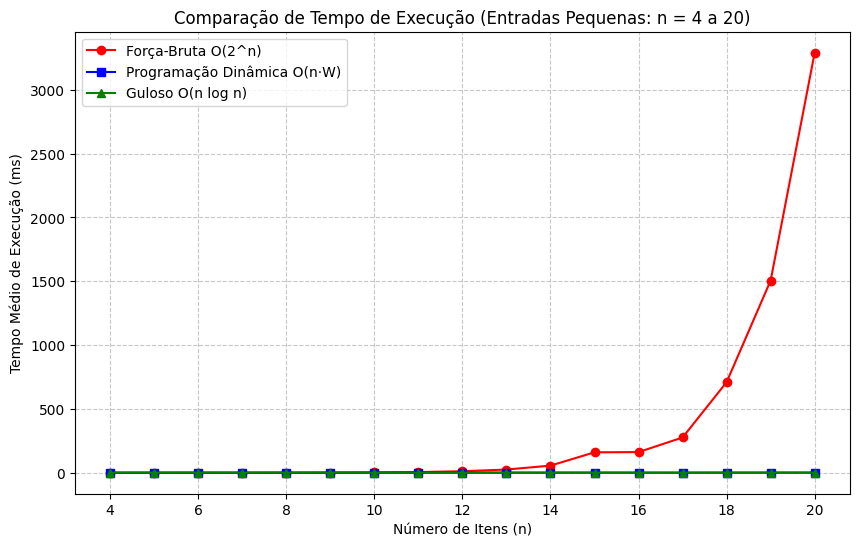

In [2]:
random.seed(42)

tamanhos_pequenos = list(range(4, 21))
execucoes_por_n = 10

tempos_guloso_1 = []
tempos_fb_1 = []
tempos_pd_1 = []

for n in tamanhos_pequenos:
    t_g, t_fb, t_pd = 0.0, 0.0, 0.0
    capacidade = n * 15

    for _ in range(execucoes_por_n):
        pesos = [random.randint(1, 30) for _ in range(n)]
        valores = [random.randint(10, 100) for _ in range(n)]

        ini = time.perf_counter()
        val_g, _ = mochila_gulosa(pesos, valores, capacidade)
        t_g += (time.perf_counter() - ini)

        ini = time.perf_counter()
        val_fb, _ = mochila_forca_bruta(pesos, valores, capacidade)
        t_fb += (time.perf_counter() - ini)

        ini = time.perf_counter()
        val_pd, _ = mochila_pd(pesos, valores, capacidade)
        t_pd += (time.perf_counter() - ini)

        assert val_fb == val_pd, f"Erro: FB ({val_fb}) != PD ({val_pd})"
        assert val_pd >= val_g, f"Erro: PD ({val_pd}) < Guloso ({val_g})"

    tempos_guloso_1.append((t_g / execucoes_por_n) * 1000)
    tempos_fb_1.append((t_fb / execucoes_por_n) * 1000)
    tempos_pd_1.append((t_pd / execucoes_por_n) * 1000)

plt.figure(figsize=(10, 6))
plt.plot(tamanhos_pequenos, tempos_fb_1, label='Força-Bruta O(2^n)', marker='o', color='red')
plt.plot(tamanhos_pequenos, tempos_pd_1, label='Programação Dinâmica O(n·W)', marker='s', color='blue')
plt.plot(tamanhos_pequenos, tempos_guloso_1, label='Guloso O(n log n)', marker='^', color='green')

plt.title('Comparação de Tempo de Execução (Entradas Pequenas: n = 4 a 20)')
plt.xlabel('Número de Itens (n)')
plt.ylabel('Tempo Médio de Execução (ms)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

# Experimento 2 — Escalabilidade (Guloso vs. PD) e Estatísticas de Qualidade

Aqui seguimos a sugestão de usar 100 tamanhos de entrada distintos (ex: $n = 10$ até $n = 1000$, com 10 execuções cada) para analisar o crescimento da Programação Dinâmica contra o Guloso e calcular a média e o desvio padrão de o quanto a PD supera o Guloso.   

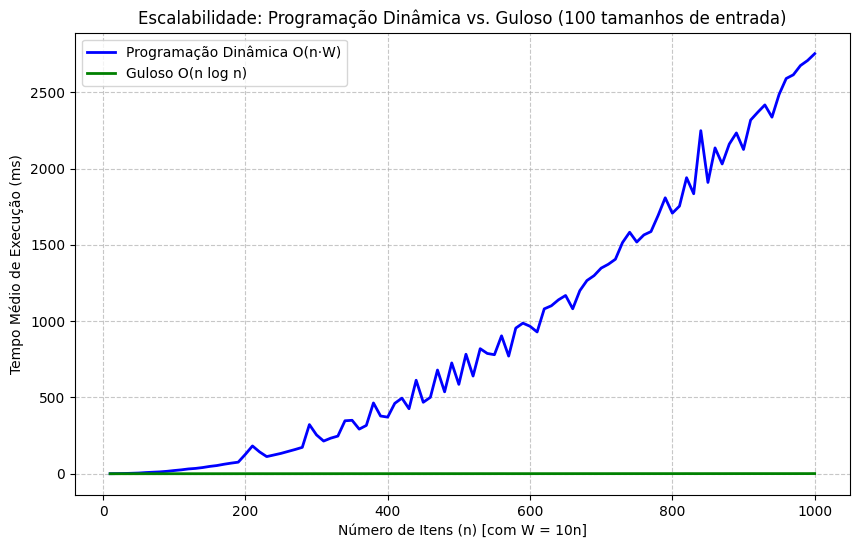

=== ANÁLISE DE QUALIDADE DA SOLUÇÃO (PD vs. GULOSO) ===
Total de instâncias testadas: 1000
Ganho Absoluto da PD -> Média: 4.45 | Desvio Padrão: 4.32
Ganho Percentual da PD -> Média: 0.06% | Desvio Padrão: 0.30%


In [3]:
tamanhos_grandes = np.linspace(10, 1000, 100, dtype=int)
execucoes_por_n = 10

tempos_guloso_2 = []
tempos_pd_2 = []
diferencas_percentuais = []
diferencas_absolutas = []

for n in tamanhos_grandes:
    t_g, t_pd = 0.0, 0.0
    capacidade = int(n * 10)

    for _ in range(execucoes_por_n):
        pesos = [random.randint(1, 30) for _ in range(n)]
        valores = [random.randint(10, 100) for _ in range(n)]

        ini = time.perf_counter()
        val_g, _ = mochila_gulosa(pesos, valores, capacidade)
        t_g += (time.perf_counter() - ini)

        ini = time.perf_counter()
        val_pd, _ = mochila_pd(pesos, valores, capacidade)
        t_pd += (time.perf_counter() - ini)

        assert val_pd >= val_g

        diff_abs = val_pd - val_g
        diff_pct = ((val_pd - val_g) / val_g * 100) if val_g > 0 else 0.0
        diferencas_absolutas.append(diff_abs)
        diferencas_percentuais.append(diff_pct)

    tempos_guloso_2.append((t_g / execucoes_por_n) * 1000)
    tempos_pd_2.append((t_pd / execucoes_por_n) * 1000)

plt.figure(figsize=(10, 6))
plt.plot(tamanhos_grandes, tempos_pd_2, label='Programação Dinâmica O(n·W)', color='blue', linewidth=2)
plt.plot(tamanhos_grandes, tempos_guloso_2, label='Guloso O(n log n)', color='green', linewidth=2)

plt.title('Escalabilidade: Programação Dinâmica vs. Guloso (100 tamanhos de entrada)')
plt.xlabel('Número de Itens (n) [com W = 10n]')
plt.ylabel('Tempo Médio de Execução (ms)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

media_abs = np.mean(diferencas_absolutas)
dp_abs = np.std(diferencas_absolutas)
media_pct = np.mean(diferencas_percentuais)
dp_pct = np.std(diferencas_percentuais)

print("=== ANÁLISE DE QUALIDADE DA SOLUÇÃO (PD vs. GULOSO) ===")
print(f"Total de instâncias testadas: {len(diferencas_absolutas)}")
print(f"Ganho Absoluto da PD -> Média: {media_abs:.2f} | Desvio Padrão: {dp_abs:.2f}")
print(f"Ganho Percentual da PD -> Média: {media_pct:.2f}% | Desvio Padrão: {dp_pct:.2f}%")

# Código extra para o gráfico da capacidade ($W$)

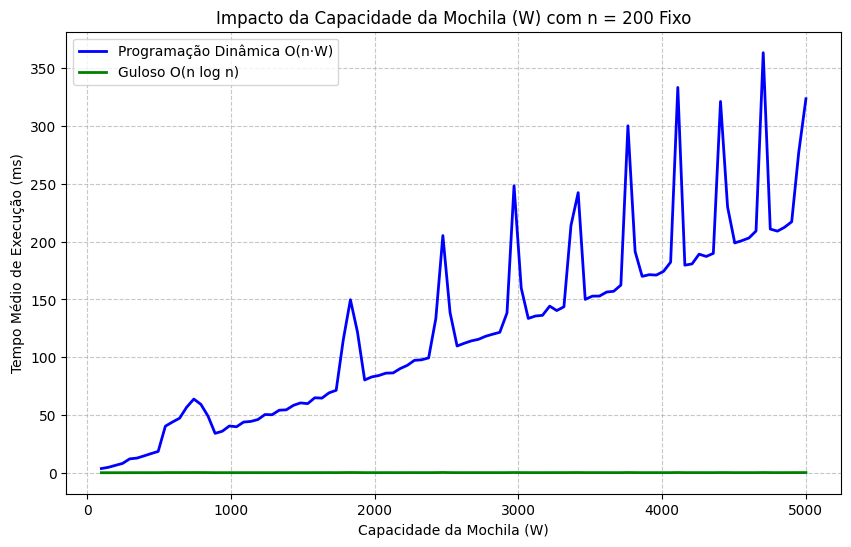

In [4]:
n_fixo = 200
capacidades = np.linspace(100, 5000, 100, dtype=int)
execucoes_por_w = 10

tempos_guloso_w = []
tempos_pd_w = []

for w_cap in capacidades:
    t_g, t_pd = 0.0, 0.0
    for _ in range(execucoes_por_w):
        pesos = [random.randint(1, 30) for _ in range(n_fixo)]
        valores = [random.randint(10, 100) for _ in range(n_fixo)]

        ini = time.perf_counter()
        val_g, _ = mochila_gulosa(pesos, valores, w_cap)
        t_g += (time.perf_counter() - ini)

        ini = time.perf_counter()
        val_pd, _ = mochila_pd(pesos, valores, w_cap)
        t_pd += (time.perf_counter() - ini)

        assert val_pd >= val_g

    tempos_guloso_w.append((t_g / execucoes_por_w) * 1000)
    tempos_pd_w.append((t_pd / execucoes_por_w) * 1000)

plt.figure(figsize=(10, 6))
plt.plot(capacidades, tempos_pd_w, label='Programação Dinâmica O(n·W)', color='blue', linewidth=2)
plt.plot(capacidades, tempos_guloso_w, label='Guloso O(n log n)', color='green', linewidth=2)

plt.title('Impacto da Capacidade da Mochila (W) com n = 200 Fixo')
plt.xlabel('Capacidade da Mochila (W)')
plt.ylabel('Tempo Médio de Execução (ms)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

## Discussão dos Resultados e Análise Crítica

### 1. Comportamento Assintótico vs. Desempenho Experimental
Os experimentos realizados confirmam empiricamente as classes de complexidade teórica de cada abordagem para o Problema da Mochila 0/1 (Tema 7.10 – Logistech):

* **Força-Bruta Ingênuo — $O(2^n)$:** No primeiro experimento ($n = 4$ a $20$), o tempo de execução manteve-se próximo de zero até $n = 14$, mas cresceu de forma abrupta a partir desse ponto, atingindo quase **3.000 ms (3 segundos)** em média já para $n = 20$. Isso demonstra na prática a inviabilidade computacional de explorar todo o espaço de subconjuntos para instâncias reais de logística.
* **Programação Dinâmica (Bottom-Up) — $O(n \cdot W)$:** Como a capacidade da mochila foi escalonada proporcionalmente ao número de itens ($W = 10n$), a complexidade teórica comportou-se como $O(10n^2) = O(n^2)$. No segundo experimento ($100$ tamanhos distintos até $n = 1000$), a curva azul exibe exatamente o formato parabólico esperado de um algoritmo quadrático, alcançando cerca de **2.750 ms** para $n = 1000$ ($W = 10.000$). As pequenas oscilações na curva refletem variações normais de alocação de memória e escalonamento da CPU no ambiente virtualizado do Google Colab.
* **Algoritmo Guloso Ingênuo — $O(n \log n)$:** Baseado apenas na ordenação decrescente da razão $\text{valor}/\text{peso}$, apresentou o menor custo computacional em todas as faixas testadas, mantendo-se praticamente plano próximo a **0 ms** mesmo para $n = 1000$.

* **Impacto da Capacidade da Mochila ($W$ variando com $n = 200$ fixo):** No terceiro experimento, ao manter a quantidade de itens constante e variar a capacidade $W$ de $100$ a $5.000$, a Programação Dinâmica apresentou crescimento linear $O(W)$ (subindo de aproximadamente $5\text{ ms}$ para cerca de $220\text{ ms}$ na linha base, com picos pontuais decorrentes da coleta de lixo (*garbage collection*) de memória do Python), confirmando sua natureza pseudo-polinomial $O(n \cdot W)$. Já o Algoritmo Guloso manteve-se constante próximo a $0\text{ ms}$, pois sua complexidade $O(n \log n)$ depende exclusivamente da ordenação dos itens e não da capacidade do veículo

### 2. Compromisso entre Tempo de Execução e Otimalidade da Solução
A validação cruzada via `assert` comprovou que a Programação Dinâmica obteve **100% de concordância com o valor ótimo** encontrado pelo Força-Bruta nas instâncias pequenas e **superou ou igualou o Algoritmo Guloso** em todas as **1.000 instâncias** testadas no experimento de escalabilidade:

* **Ganho Absoluto da PD sobre o Guloso:** Média de **$4,45$** unidades de valor (Desvio Padrão: **$4,32$**).
* **Ganho Percentual da PD sobre o Guloso:** Média de **$0,06\%$** (Desvio Padrão: **$0,30\%$**).

Embora o ganho percentual médio pareça pequeno neste cenário aleatório uniforme (onde $W = 10n$ permite acomodar grande parte dos itens de maior razão), o algoritmo guloso **não oferece garantia de otimalidade**, pois decisões locais ótimas podem deixar capacidade residual ociosa na mochila que seria melhor aproveitada por uma combinação alternativa de itens.

### 3. Conclusão
Para sistemas logísticos reais com dezenas ou centenas de produtos, o algoritmo de **Força-Bruta** é impraticável. A **Programação Dinâmica** representa o melhor equilíbrio quando o objetivo é maximizar rigorosamente o valor transportado, entregando a solução ótima exata (tanto o valor máximo quanto o subconjunto específico de itens) em tempo polinomial viável. Já a abordagem **Guloso** mostra-se útil apenas como heurística rápida quando o tempo de resposta em milissegundos é crítico e pequenas perdas de eficiência são toleráveis.